In [15]:
from IPython import display
import ultralytics

In [16]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [17]:
import cv2
import matplotlib.pyplot as plt

In [18]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cpu CPU (Intel Core i5-14500)
Setup complete  (20 CPUs, 31.7 GB RAM, 64.4/1862.9 GB disk)


In [19]:
model = ultralytics.YOLO('yolo26n.yaml').load('yolo26n.pt')

Transferred 708/708 items from pretrained weights


In [20]:
img = "dataset/data/f7a63fde-f06b61b8-00d0c59b405175a1.jpg"
result = model.predict(img)


image 1/1 d:\ml_s2\projectyolo\dataset\data\f7a63fde-f06b61b8-00d0c59b405175a1.jpg: 448x640 1 15, 57.2ms
Speed: 3.4ms preprocess, 57.2ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


1
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([15.])
conf: tensor([0.8839])
data: tensor([[318.9696, 110.6681, 759.7855, 630.7060,   0.8839,  15.0000]])
id: None
is_track: False
orig_shape: (683, 1024)
shape: torch.Size([1, 6])
xywh: tensor([[539.3776, 370.6870, 440.8159, 520.0379]])
xywhn: tensor([[0.5267, 0.5427, 0.4305, 0.7614]])
xyxy: tensor([[318.9696, 110.6681, 759.7855, 630.7060]])
xyxyn: tensor([[0.3115, 0.1620, 0.7420, 0.9234]])
15
[319, 111, 760, 631]
0.88


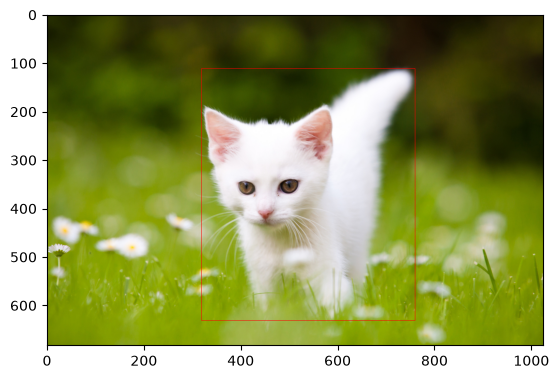

In [24]:
print(len(result[0].boxes))
myimage = cv2.imread(img)
myimage = cv2.cvtColor(myimage, cv2.COLOR_BGR2RGB)
plt.imshow(myimage)

for box in result[0].boxes:
    print(box)
    class_id = result[0].names[box.cls[0].item()]
    print(class_id)
    coor = box.xyxy[0].tolist()
    coors = [round(x)for x in coor ]
    print(coors)
    cf = round(box.conf[0].item(),2)
    print(cf)
    myimage = cv2.rectangle(myimage,(coors[0],coors[1]),(coors[2],coors[3]),(255,0,0))
plt.imshow(myimage)